# Honolulu traffic camera locations

Exploratory cleaning and feature engineering for the included 253-row camera-location CSV. The notebook parses coordinates, adds a road-name keyword flag and longitude bins, scales coordinates, and plots the resulting distribution. The road flag and bins are heuristics, not validated geographic or traffic classifications. Run Jupyter from this project folder so `data/Traffic_Camera_Locations.csv` resolves. No prediction model is trained or evaluated here.

ORIGINAL TRAFFIC CAMERA DATA LOADED
                     Description CameraImageURL                  Location
0             ATKINSON & KAHAKAI            NaN  (21.290416, -157.837953)
1           BERETANIA & MAUNAKEA            NaN  (21.313588, -157.861214)
2           BERETANIA & RICHARDS            NaN  (21.309086, -157.857548)
3                    DUKE CAMERA            NaN  (21.278221, -157.827902)
4        FARRINGTON & KAPOWAI PL            NaN  (21.338024, -158.079195)
5         FARRINGTON & KEALANANI            NaN  (21.342366, -158.072594)
6            FARRINGTON & LAALOA            NaN  (21.342083, -158.106873)
7       FARRINGTON & MAKAKILO DR            NaN  (21.340359, -158.076093)
8       FARRINGTON & MAKAKILO DR            NaN   (21.34012, -158.075599)
9  FARRINGTON & NOULU/PAPAIALULU            NaN    (21.34504, -158.06903)

Shape: (253, 3)

Missing values before handling:
Description         0
CameraImageURL    100
Location            1
dtype: int64

COORDINATES EXTRACTE

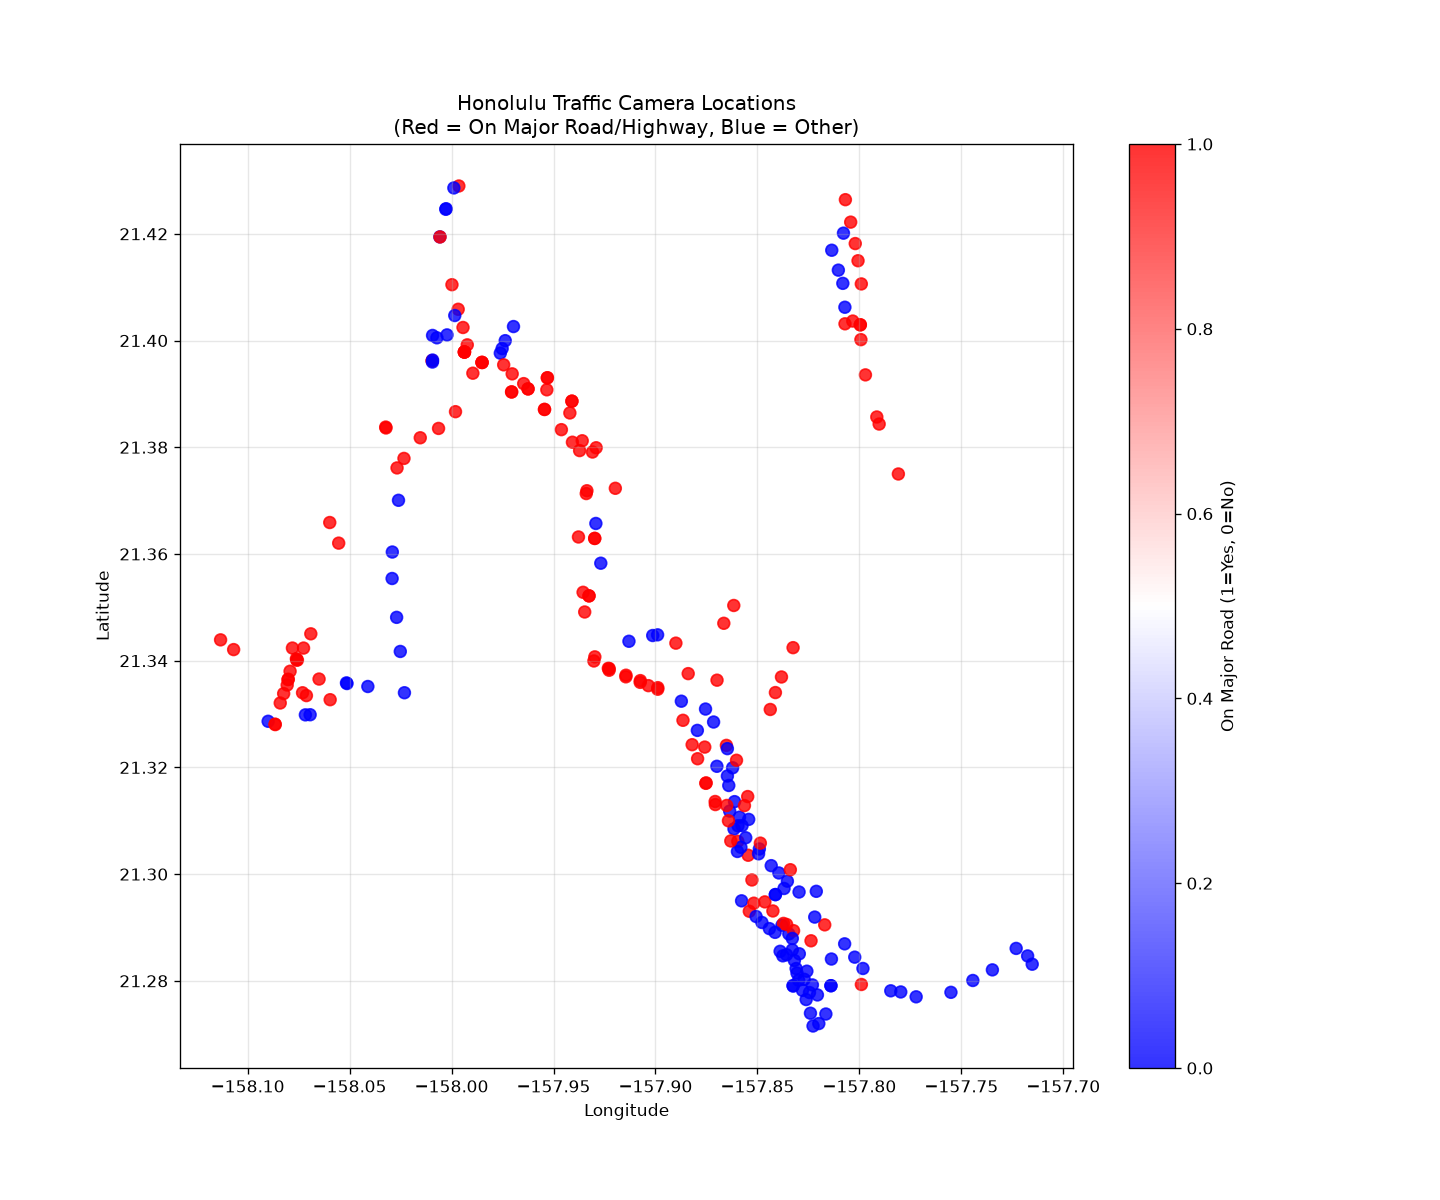

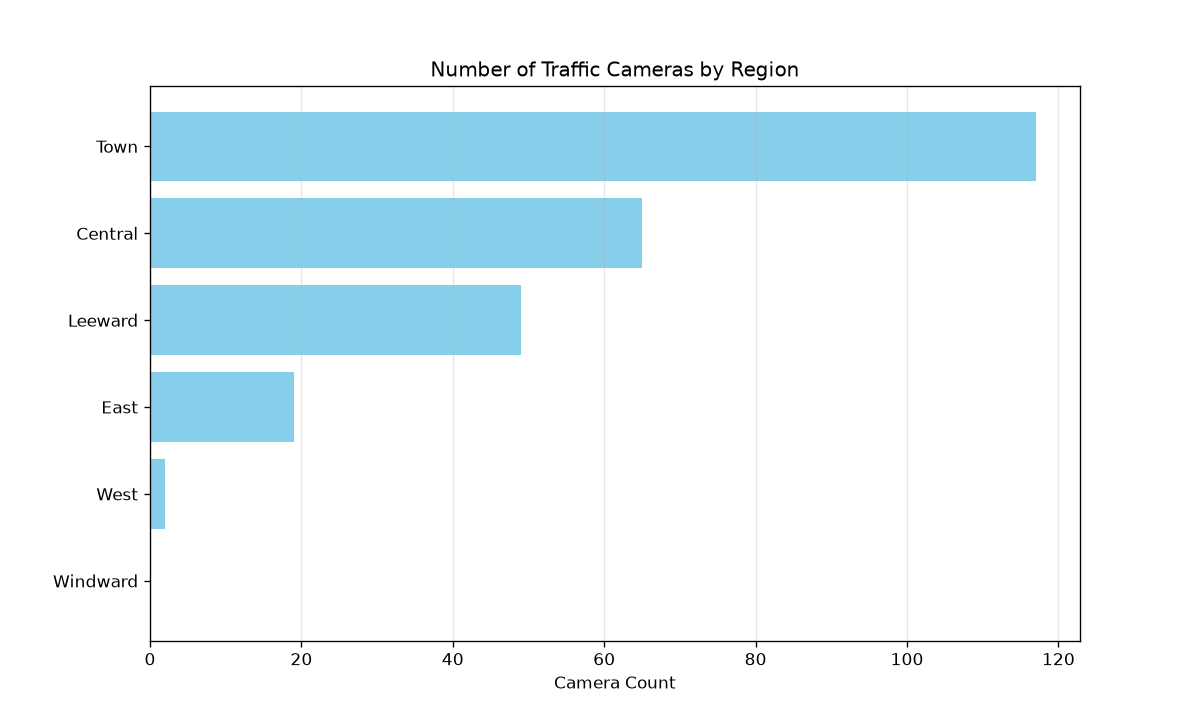

In [1]:
"""
Traffic Cameras Feature Engineering & Preprocessing Pipeline
Honolulu Traffic Camera Locations Dataset
@author: https://github.com/DocOhms/machine-learning-portfolio
Dataset: Traffic_Camera_Locations.csv (City & County of Honolulu)
Purpose: Clean geographic data, engineer location-based features for ML tasks
         (e.g., camera coverage analysis, incident proximity modeling when merged)
"""
# Import libraries 
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

class TrafficCamerasEngineering:
    def __init__(self):
        self.df = None
    
    def create_DFrame_from_csv(self, file_path="data/Traffic_Camera_Locations.csv"):
        try:
            df = pd.read_csv(file_path)
            print("ORIGINAL TRAFFIC CAMERA DATA LOADED")
            print(df.head(10))
            print(f"\nShape: {df.shape}")
            self.df = df
        except FileNotFoundError:
            print(f"Error: The file '{file_path}' was not found. Run this notebook from the traffic-preprocessing project folder.")
        except Exception as e:
            print("An error occurred:", e)
    
    def Handle_Missing_Values_and_Clean(self):
        if self.df is None:
            print("Load data first!")
            return
        
        df = self.df
        print("\nMissing values before handling:")
        print(df.isnull().sum())
        
        # Clean Location column and extract coordinates
        df['Location'] = df['Location'].astype(str).str.strip()
        df = df[df['Location'].str.startswith('(')].reset_index(drop=True)
        
        df['Latitude'] = df['Location'].str.extract(r'\(([\d\.-]+)')[0].astype(float)
        df['Longitude'] = df['Location'].str.extract(r', ([\d\.-]+)\)')[0].astype(float)
        
        df = df.dropna(subset=['Latitude', 'Longitude']).reset_index(drop=True)
        
        print("\nCOORDINATES EXTRACTED & MISSING CLEANED")
        print(df[['Description', 'Latitude', 'Longitude']].head(10))
        self.df = df
    
    def Feature_Creation(self):
        if self.df is None:
            print("Load and clean data first!")
            return
        
        df = self.df
        
        # Major road/highway flag
        major_keywords = ['H-1', 'H-2', 'H-3', 'FARRINGTON', 'KAM', 'KALANIANAOLE', 
                         'PALI', 'KAPIOLANI', 'NIMITZ', 'LIKELIKE', 'MOANALUA']
        df['OnMajorRoad'] = df['Description'].str.contains(
            '|'.join(major_keywords), case=False, na=False).astype(int)
        
        # Region categorization (fixed bin edges to match labels)
        df['Region'] = pd.cut(df['Longitude'],
                              bins=[-158.3, -158.1, -158.0, -157.9, -157.8, -157.7, -157.5],
                              labels=['West', 'Leeward', 'Central', 'Town', 'East', 'Windward'],
                              include_lowest=True)
        
        print("\nNEW CAMERA FEATURES CREATED")
        print(df[['Description', 'OnMajorRoad', 'Region']].head(15))
        self.df = df
    
    def Feature_Transformation(self):
        if self.df is None:
            print("Complete previous steps first!")
            return
        
        df = self.df
        
        # Scale coordinates for potential clustering/ML use
        scaler = StandardScaler()
        df[['Latitude_scaled', 'Longitude_scaled']] = scaler.fit_transform(
            df[['Latitude', 'Longitude']])
        
        print("\nCOORDINATES SCALED")
        print(df[['Latitude_scaled', 'Longitude_scaled', 'OnMajorRoad']].head(10))
        self.df = df
    
    def Feature_Selection_and_Visualization(self):
        if self.df is None:
            print("Complete previous steps first!")
            return
        
        df = self.df
        
        # Final modeling-ready dataframe - include Region directly
        df_model = df[['Latitude', 'Longitude', 'OnMajorRoad', 
                       'Latitude_scaled', 'Longitude_scaled', 'Region']].copy()
        
        # Visualizations (pure matplotlib only)
        print("\nCAMERA DISTRIBUTION BY MAJOR ROAD")
        print(df['OnMajorRoad'].value_counts())
        
        # Static scatter plot of camera locations
        plt.figure(figsize=(12, 10))
        scatter = plt.scatter(df['Longitude'], df['Latitude'], 
                              c=df['OnMajorRoad'], cmap='bwr', alpha=0.8, s=50)
        plt.title('Honolulu Traffic Camera Locations\n(Red = On Major Road/Highway, Blue = Other)')
        plt.xlabel('Longitude')
        plt.ylabel('Latitude')
        plt.colorbar(scatter, label='On Major Road (1=Yes, 0=No)')
        plt.grid(True, alpha=0.3)
        plt.show()
        
        # Horizontal bar plot for region distribution (pure matplotlib)
        plt.figure(figsize=(10, 6))
        region_counts = df['Region'].value_counts().sort_values()
        plt.barh([str(r) for r in region_counts.index], region_counts.values, color='skyblue')
        plt.title('Number of Traffic Cameras by Region')
        plt.xlabel('Camera Count')
        plt.grid(True, alpha=0.3, axis='x')
        plt.show()
        
        print("\nENGINEERED CAMERA FEATURE TABLE")
        print(df_model.head(10))
        print(f"\nFinal shape: {df_model.shape}")
        self.df_final = df_model

# ---------------------------- Class Driver ----------------------------
cameras = TrafficCamerasEngineering()
cameras.create_DFrame_from_csv("data/Traffic_Camera_Locations.csv")
cameras.Handle_Missing_Values_and_Clean()
cameras.Feature_Creation()
cameras.Feature_Transformation()
cameras.Feature_Selection_and_Visualization()